In [1]:
##importing Libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns 
import numpy as np

In [2]:
## data_preprocessing

In [3]:
training_set = tf.keras.utils.image_dataset_from_directory(
    'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 70295 files belonging to 38 classes.


In [4]:
training_set = tf.keras.utils.image_dataset_from_directory(
    'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 70295 files belonging to 38 classes.


In [5]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 17572 files belonging to 38 classes.


In [6]:
training_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

In [7]:
for x,y in training_set:
    print(x,x.shape)
    printy=(y,y.shape)
    break 

tf.Tensor(
[[[[153.5  141.5  141.5 ]
   [149.   137.   137.  ]
   [161.   149.   149.  ]
   ...
   [154.25 140.25 140.25]
   [153.5  139.5  139.5 ]
   [165.25 151.25 151.25]]

  [[156.5  144.5  144.5 ]
   [148.75 136.75 136.75]
   [153.   141.   141.  ]
   ...
   [156.5  142.5  142.5 ]
   [161.75 147.75 147.75]
   [155.   141.   141.  ]]

  [[158.   146.   146.  ]
   [160.   148.   148.  ]
   [152.25 140.25 140.25]
   ...
   [152.25 138.25 138.25]
   [145.5  131.5  131.5 ]
   [154.5  140.5  140.5 ]]

  ...

  [[172.25 160.25 160.25]
   [165.   153.   153.  ]
   [161.75 149.75 149.75]
   ...
   [169.25 157.25 161.25]
   [168.   156.   160.  ]
   [161.75 149.75 153.75]]

  [[158.75 146.75 146.75]
   [164.25 152.25 152.25]
   [161.75 149.75 149.75]
   ...
   [152.5  140.5  144.5 ]
   [160.5  148.5  152.5 ]
   [180.   168.   172.  ]]

  [[161.25 149.25 149.25]
   [173.   161.   161.  ]
   [165.5  153.5  153.5 ]
   ...
   [160.5  148.5  152.5 ]
   [158.5  146.5  150.5 ]
   [153.75 141.75 14

In [8]:
##building the model

In [9]:
from tensorflow.keras.layers import Dense,Conv2D,MaxPool2D,Flatten,Dense,Dropout
from tensorflow.keras.models import Sequential

In [10]:
model =  tf.keras.models.Sequential()

In [11]:
## building convolutional layers 

In [12]:
model.add(Conv2D(filters=32,kernel_size=3,padding='same', activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=32,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

C:\Users\asmit\anaconda34\envs\tensorflow_env\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
model.add(Conv2D(filters=64,kernel_size=3,padding='same', activation='relu'))
model.add(Conv2D(filters=64,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [14]:
model.add(Conv2D(filters=128,kernel_size=3,padding='same', activation='relu'))
model.add(Conv2D(filters=128,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [15]:
model.add(Conv2D(filters=256,kernel_size=3,padding='same', activation='relu'))
model.add(Conv2D(filters=256,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [16]:
model.add(Conv2D(filters=512,kernel_size=3,padding='same', activation='relu'))
model.add(Conv2D(filters=512,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [17]:
model.add(Dropout(0.25))

In [18]:
model.add(Flatten())

In [19]:
model.add(Dense(units=1500,activation='relu'))

In [20]:
model.add(Dropout(0.4))

In [21]:
##output layer
model.add(Dense(units=38,activation='softmax'))

In [22]:
##Compiling Model

In [23]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 126, 126, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 63, 63, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 61, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 30, 30, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 14, 14, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 12, 12, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 6, 6, 512)           │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 4, 4, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 2, 2, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2, 2, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1500)                │       3,073,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1500)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 38)                  │          57,038 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,842,762 (29.92 MB)

 Trainable params: 7,842,762 (29.92 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
import json

with open('training_hist.json', 'r') as f:
    history = json.load(f)
print(history) 

{'accuracy': [0.5950921177864075, 0.8544562458992004, 0.9098228812217712, 0.9383313059806824, 0.9532968401908875, 0.9636958241462708, 0.9700832366943359, 0.9748488664627075, 0.9797567129135132, 0.9808805584907532], 'loss': [1.3778687715530396, 0.4590107798576355, 0.279880166053772, 0.18991288542747498, 0.14087437093257904, 0.10942903906106949, 0.0919046700000763, 0.07568718492984772, 0.06261361390352249, 0.058725547045469284], 'val_accuracy': [0.8527202606201172, 0.9029706120491028, 0.915831983089447, 0.9380264282226562, 0.9486114382743835, 0.9400750994682312, 0.9522535800933838, 0.9692124128341675, 0.9620987772941589, 0.9454814195632935], 'val_loss': [0.4859358072280884, 0.3073507845401764, 0.2560434639453888, 0.19730575382709503, 0.1735544204711914, 0.19016781449317932, 0.15845118463039398, 0.10315101593732834, 0.12821035087108612, 0.2009330540895462]}


In [40]:
##Model Training

In [60]:
training_history = model.fit(x=training_set,validation_data=validation_set,epochs=10)

Epoch 1/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 2442s 1s/step - accuracy: 0.3979 - loss: 2.1530 - val_accuracy: 0.8527 - val_loss: 0.4859
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 3445s 2s/step - accuracy: 0.8316 - loss: 0.5333 - val_accuracy: 0.9030 - val_loss: 0.3074
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 2335s 1s/step - accuracy: 0.9008 - loss: 0.3072 - val_accuracy: 0.9158 - val_loss: 0.2560
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 2290s 1s/step - accuracy: 0.9347 - loss: 0.2022 - val_accuracy: 0.9380 - val_loss: 0.1973
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 3039s 1s/step - accuracy: 0.9496 - loss: 0.1515 - val_accuracy: 0.9486 - val_loss: 0.1736
Epoch 6/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 3102s 1s/step - accuracy: 0.9610 - loss: 0.1172 - val_accuracy: 0.9401 - val_loss: 0.1902
Epoch 7/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 3000s 1s/step - accuracy: 0.9681 - loss: 0.0979 - val_accuracy: 0.9523 - val_loss: 0.1585
Epoch 8/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 2715s 1s/step - accuracy: 0.9744 -

In [26]:
##Model Evaluation

In [26]:
from tensorflow import keras
model = keras.models.load_model("trained_model.keras") 


C:\Users\asmit\anaconda34\envs\tensorflow_env\lib\site-packages\keras\src\saving\saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 26 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [62]:
train_loss,train_acc = model.evaluate(training_set)

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 789s 359ms/step - accuracy: 0.9729 - loss: 0.0934


In [63]:
print(train_loss,train_acc)

0.09166719019412994 0.9743082523345947


In [65]:
val_loss,val_acc = model.evaluate(validation_set)

550/550 ━━━━━━━━━━━━━━━━━━━━ 183s 332ms/step - accuracy: 0.9466 - loss: 0.1965


In [66]:
print(val_loss,val_acc)

0.20093317329883575 0.9454814195632935


In [67]:
##Saving Model 

In [30]:
# model.save("trained_model.keras")

In [36]:
# training_history.history

In [71]:
import json
with open("training_hist.json","w") as f:
    json.dump(training_history.history,f)

##Accuracy visualzation

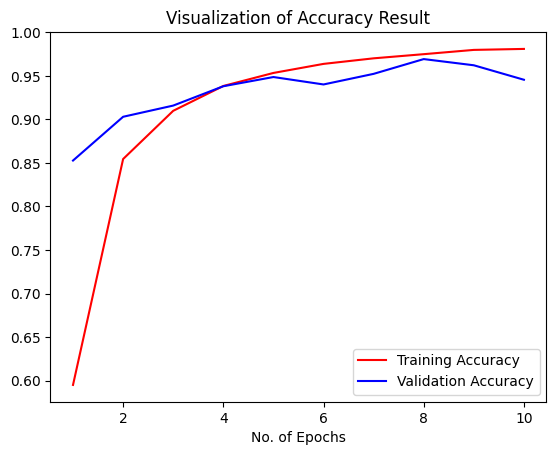

In [27]:
with open('training_hist.json', 'r') as f:
    history = json.load(f) 

    epochs = [i for i in range(1, len(history['accuracy']) + 1)]

epochs = [i for i in range(1,11)]
plt.plot(epochs,history['accuracy'],color='red',label='Training Accuracy')
plt.plot(epochs,history['val_accuracy'],color='blue',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()

#model evaluation

In [37]:
class_name = validation_set.class_names
class_name

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [38]:
test_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 17572 files belonging to 38 classes.


In [29]:
y_pred = model.predict(test_set)
y_pred

550/550 ━━━━━━━━━━━━━━━━━━━━ 264s 479ms/step


array([[9.99331594e-01, 6.98632502e-05, 4.54840165e-06, ...,
        7.91117949e-10, 2.28952080e-09, 1.09879558e-07],
       [8.74653518e-01, 4.64914716e-04, 3.00848566e-04, ...,
        2.50377610e-07, 1.06850564e-06, 1.21145285e-05],
       [1.00000000e+00, 2.64661265e-10, 1.23224791e-10, ...,
        9.33382662e-18, 3.94105542e-15, 1.12513005e-12],
       ...,
       [2.97483365e-13, 3.74580543e-15, 6.72089884e-11, ...,
        2.31586465e-14, 3.97756203e-14, 9.99999881e-01],
       [2.49858779e-11, 3.33698286e-14, 3.20982546e-10, ...,
        8.04488258e-13, 2.09221841e-13, 9.99999881e-01],
       [3.76161674e-14, 9.99167840e-18, 5.97781983e-14, ...,
        4.39812064e-17, 2.81444019e-15, 1.00000000e+00]], dtype=float32)

In [30]:
predicted_categories = tf.argmax(y_pred,axis=1)

In [31]:
predicted_categories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37])>

In [32]:
true_categories = tf.concat([y for x,y in test_set],axis=0)
true_categories

<tf.Tensor: shape=(17572, 38), dtype=float32, numpy=
array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]], dtype=float32)>

In [33]:
Y_true = tf.argmax(true_categories,axis=1)
Y_true

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37])>

##precision recall

In [40]:
from sklearn.metrics import classification_report,confusion_matrix 
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.84      0.91       504
                                 Apple___Black_rot       0.98      0.97      0.98       497
                          Apple___Cedar_apple_rust       0.84      0.99      0.91       440
                                   Apple___healthy       0.90      0.98      0.94       502
                               Blueberry___healthy       0.98      0.93      0.95       454
          Cherry_(including_sour)___Powdery_mildew       0.96      0.98      0.97       421
                 Cherry_(including_sour)___healthy       0.96      0.98      0.97       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.91      0.93      0.92       410
                       Corn_(maize)___Common_rust_       0.99      1.00      0.99       477
               Corn_(maize)___Northern_Leaf_Blight       0.94      0.95      0.

In [41]:
cm = confusion_matrix(Y_true,predicted_categories)
cm

array([[425,   2,  16, ...,   0,   0,   2],
       [  0, 484,   1, ...,   0,   0,   0],
       [  0,   0, 435, ...,   0,   0,   1],
       ...,
       [  0,   0,   0, ..., 487,   0,   0],
       [  0,   0,   1, ...,   0, 424,   2],
       [  0,   0,   0, ...,   0,   0, 481]])

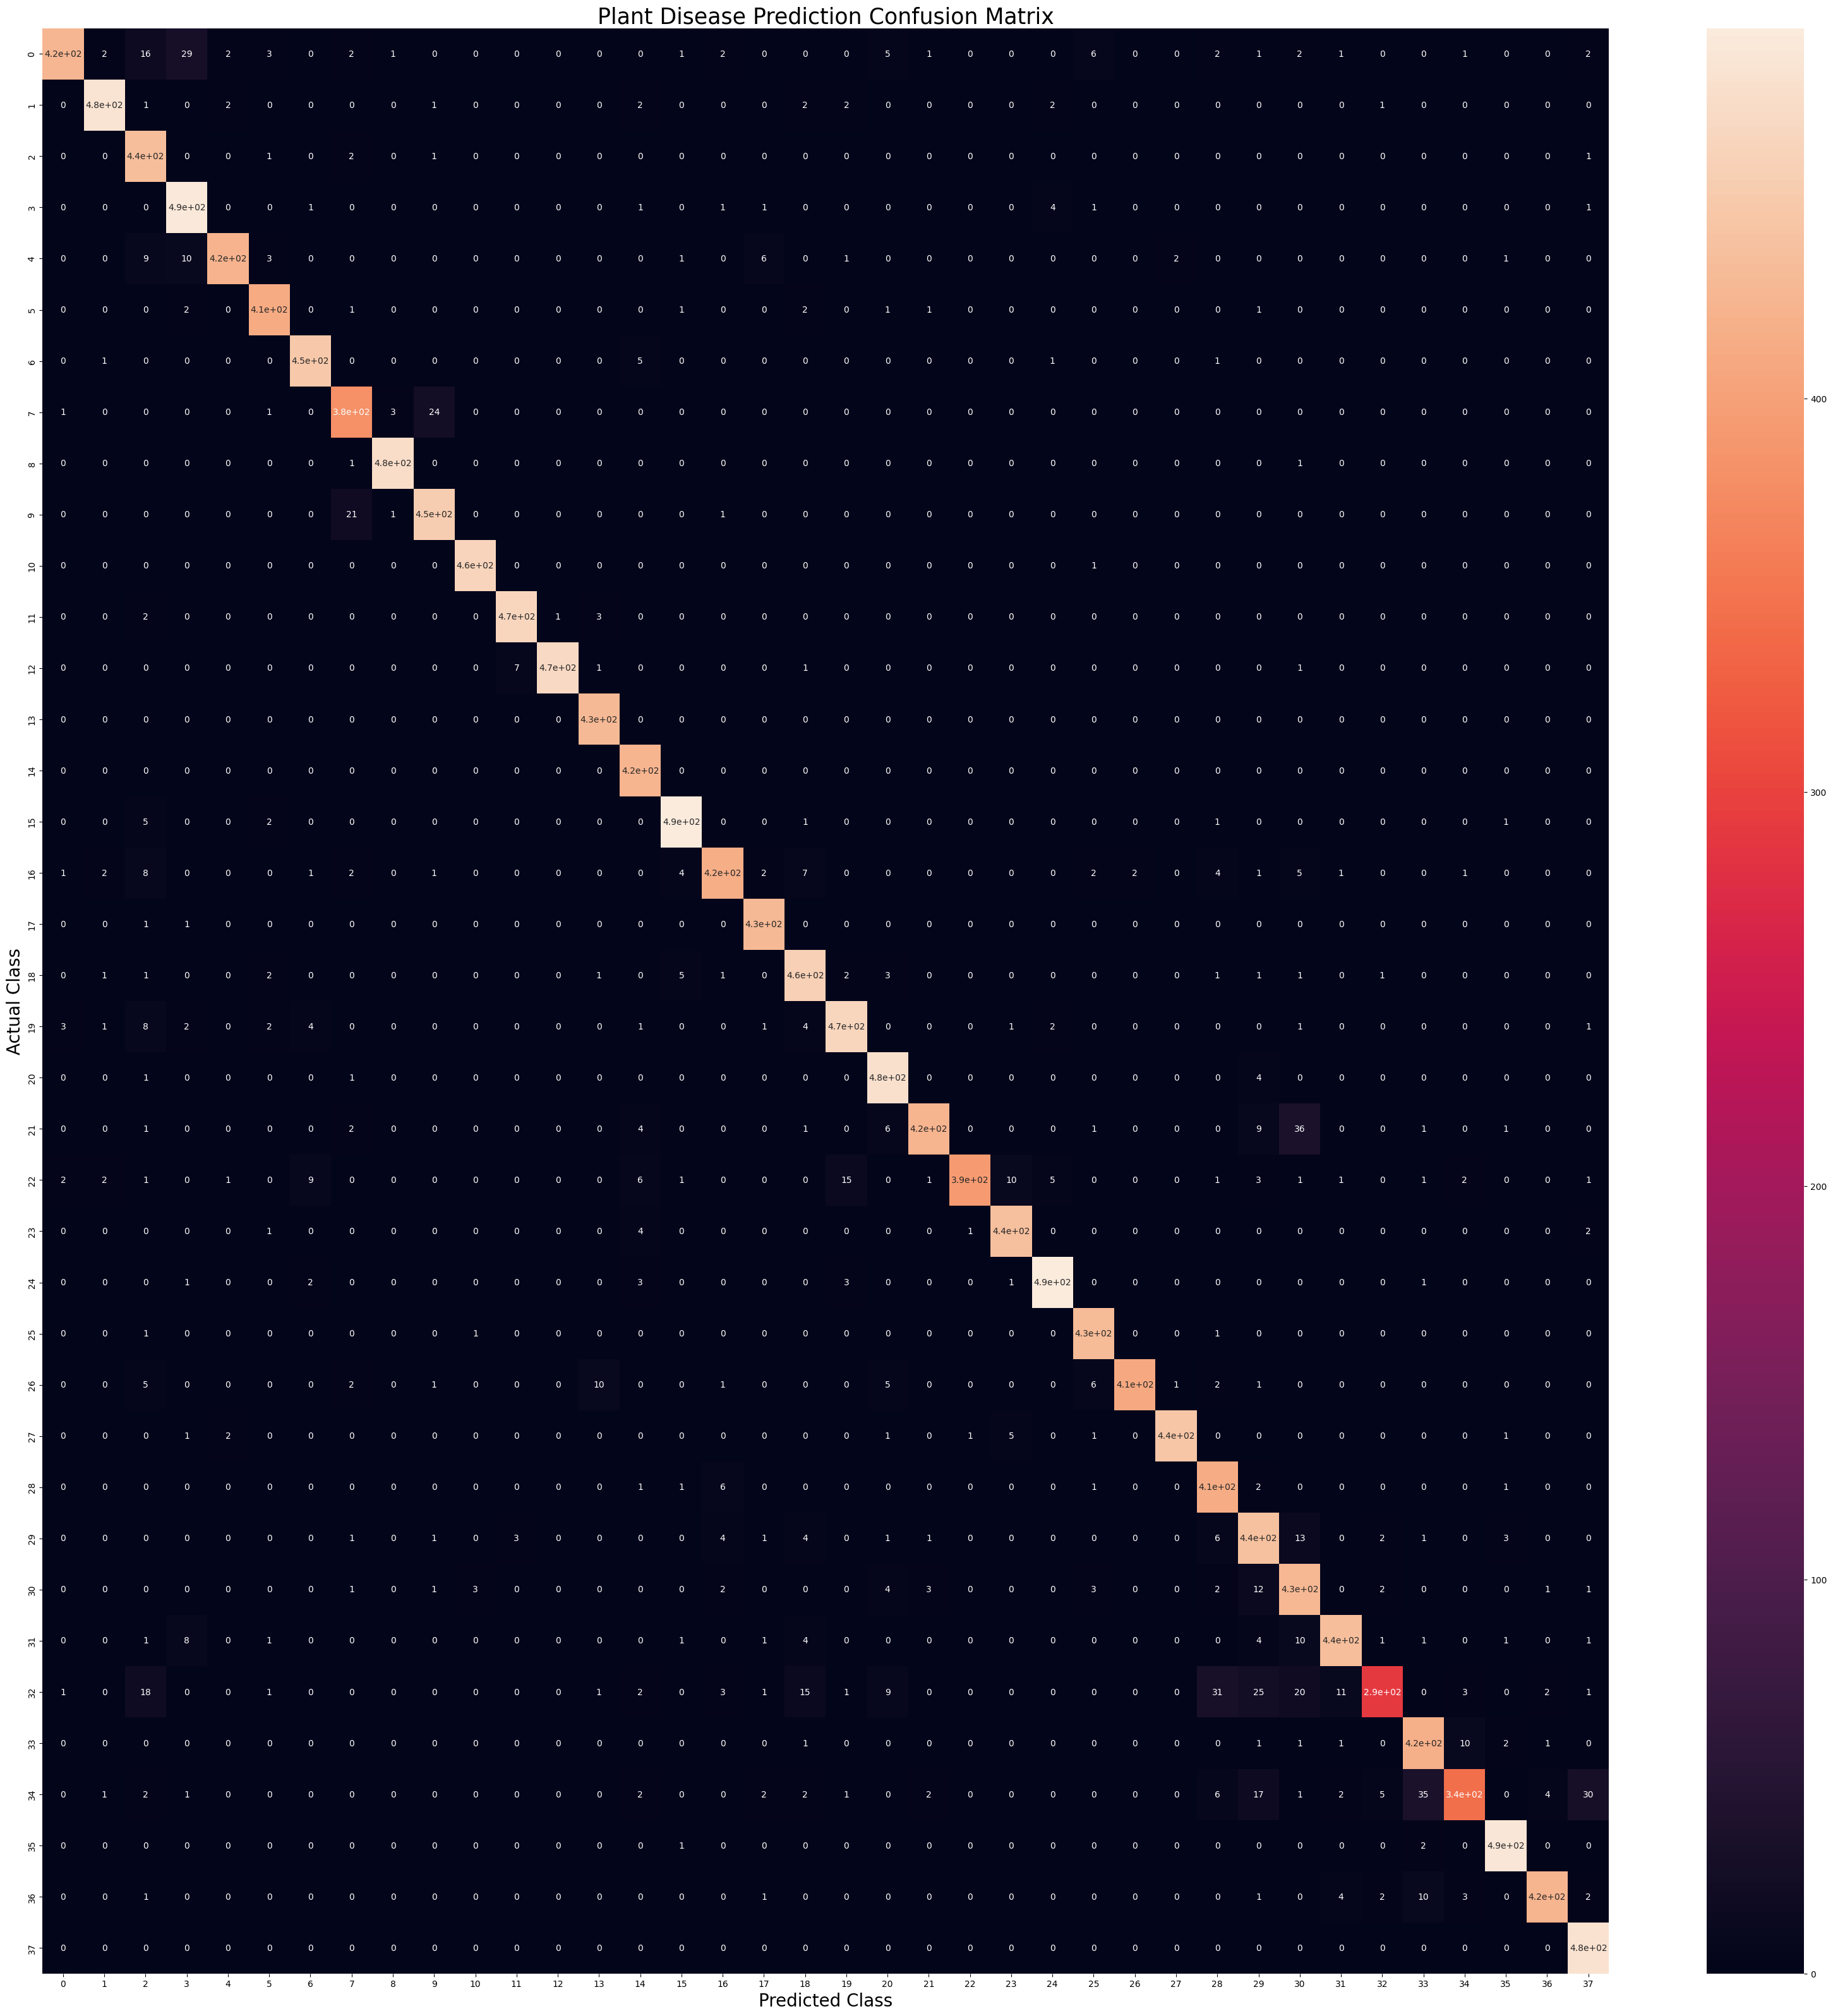

In [46]:
plt.figure(figsize=(40,40))
sns.heatmap(cm,annot=True,annot_kws={'size':10})
plt.xlabel("Predicted Class", fontsize=20)
plt.ylabel("Actual Class", fontsize=20)
plt.title("Plant Disease Prediction Confusion Matrix",fontsize=25)
plt.show()